In [1]:
from itertools import combinations
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

outputdir = "./SBS_single_change_graph"
os.system(f"mkdir -p {outputdir}")

0

# Create SBS graph - single-change between SBSs

## Preparation

In [ ]:
BASES = ["A", "C", "G", "T"]
SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]

sbs96 = pd.Index(sorted(f"{f}[{s}]{t}" for f in BASES for s in SUBS for t in BASES), name="MutationType")
parts = pd.DataFrame({"prime5": sbs96.str[0], "ref": sbs96.str[2], "alt": sbs96.str[4], "prime3": sbs96.str[-1]},
                     index=sbs96)
print(len(sbs96), "SBSs;", list(sbs96[:4]), "...")
parts.head()

96 channels; ['A[C>A]A', 'A[C>A]C', 'A[C>A]G', 'A[C>A]T'] ...


,prime5,ref,alt,prime3
MutationType,,,,
A[C>A]A,A,C,A,A
A[C>A]C,A,C,A,C
A[C>A]G,A,C,A,G
A[C>A]T,A,C,A,T
A[C>G]A,A,C,G,A


## Define EDGES

In [3]:
cols = ["prime5", "ref", "alt", "prime3"]
P = parts[cols].to_numpy()
edges = []
for i, j in combinations(range(96), 2):
    diff = P[i] != P[j]
    if diff.sum() == 1:
        edges.append(dict(u=sbs96[i], v=sbs96[j], kind=cols[int(np.argmax(diff))], weight=1.0))
edges = pd.DataFrame(edges)

print(len(edges), "edges")
print(edges.kind.value_counts())
edges.head()

416 edges
kind
prime3    144
prime5    144
alt        96
ref        32
Name: count, dtype: int64


,u,v,kind,weight
0,A[C>A]A,A[C>A]C,prime3,1.0
1,A[C>A]A,A[C>A]G,prime3,1.0
2,A[C>A]A,A[C>A]T,prime3,1.0
3,A[C>A]A,A[C>G]A,alt,1.0
4,A[C>A]A,A[C>T]A,alt,1.0


## Cost matrix = shortest path on graph

In [4]:
idx = {c: k for k, c in enumerate(sbs96)}
i = edges.u.map(idx).to_numpy()
j = edges.v.map(idx).to_numpy()
A = csr_matrix((edges.weight.to_numpy(), (i, j)), shape=(96, 96))

D = shortest_path(A, directed=False)                 # graph distance, 96 x 96
assert np.isfinite(D).all(), "graph is not connected"
M = D / D.max()                                      # ground cost, max = 1

print("distances that occur:", np.unique(D))
print("max distance:", D.max(), "  mean off-diagonal cost:", M[~np.eye(96, dtype=bool)].mean().round(3))
print("examples:")
for a, b in [("A[C>A]A", "A[C>G]A"), ("A[C>A]A", "A[T>G]A"), ("A[C>T]A", "A[T>C]A"), ("A[C>A]A", "T[T>G]T")]:
    print(f"  {a} -> {b}: {D[idx[a], idx[b]]:.0f} steps")

distances that occur: [0. 1. 2. 3. 4. 5.]
max distance: 5.0   mean off-diagonal cost: 0.561
examples:
  A[C>A]A -> A[C>G]A: 1 steps
  A[C>A]A -> A[T>G]A: 2 steps
  A[C>T]A -> A[T>C]A: 3 steps
  A[C>A]A -> T[T>G]T: 4 steps


### Visualize the graph/cost matrix

neighbours per channel: {8.0: 32, 9.0: 64}


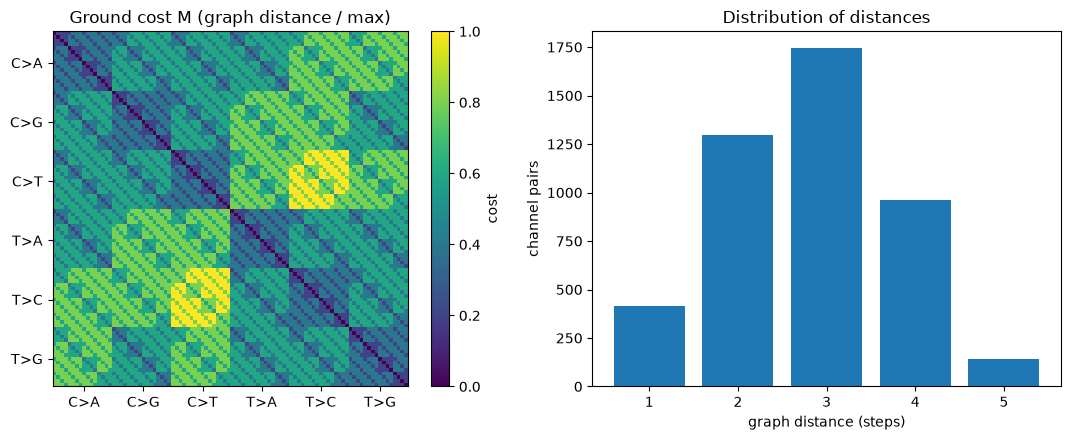

In [ ]:
deg = np.asarray((A + A.T).sum(1)).ravel()         # number of neighbours per channel (all weights 1)
print("neighbours per channel:", pd.Series(deg, index=sbs96).value_counts().sort_index().to_dict())

# cost matrix in the standard SBS96 plotting order (grouped by substitution)
order = sorted(range(96), key=lambda r: (sbs96[r][2:5], sbs96[r][0], sbs96[r][-1]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im = axes[0].imshow(M[np.ix_(order, order)], cmap="viridis")
fig.colorbar(im, ax=axes[0], label="cost")
ticks = range(8, 96, 16)
axes[0].set_xticks(ticks)
axes[0].set_xticklabels(SUBS)
axes[0].set_yticks(ticks)
axes[0].set_yticklabels(SUBS)
axes[0].set_title("Ground cost M (graph distance / max)")
axes[1].hist(D[np.triu_indices(96, 1)], bins=np.arange(0.5, D.max() + 1.5), rwidth=0.8)
axes[1].set_xlabel("graph distance (steps)")
axes[1].set_ylabel("channel pairs")
axes[1].set_title("Distribution of distances")
plt.tight_layout()
plt.show()

Save the cost matrix

In [6]:
pd.DataFrame(M, index=sbs96, columns=sbs96).to_csv(os.path.join(outputdir, "graph_M1.csv"), float_format="%.10g")

## Some more visulizations

(these nice figures are AI generated!)

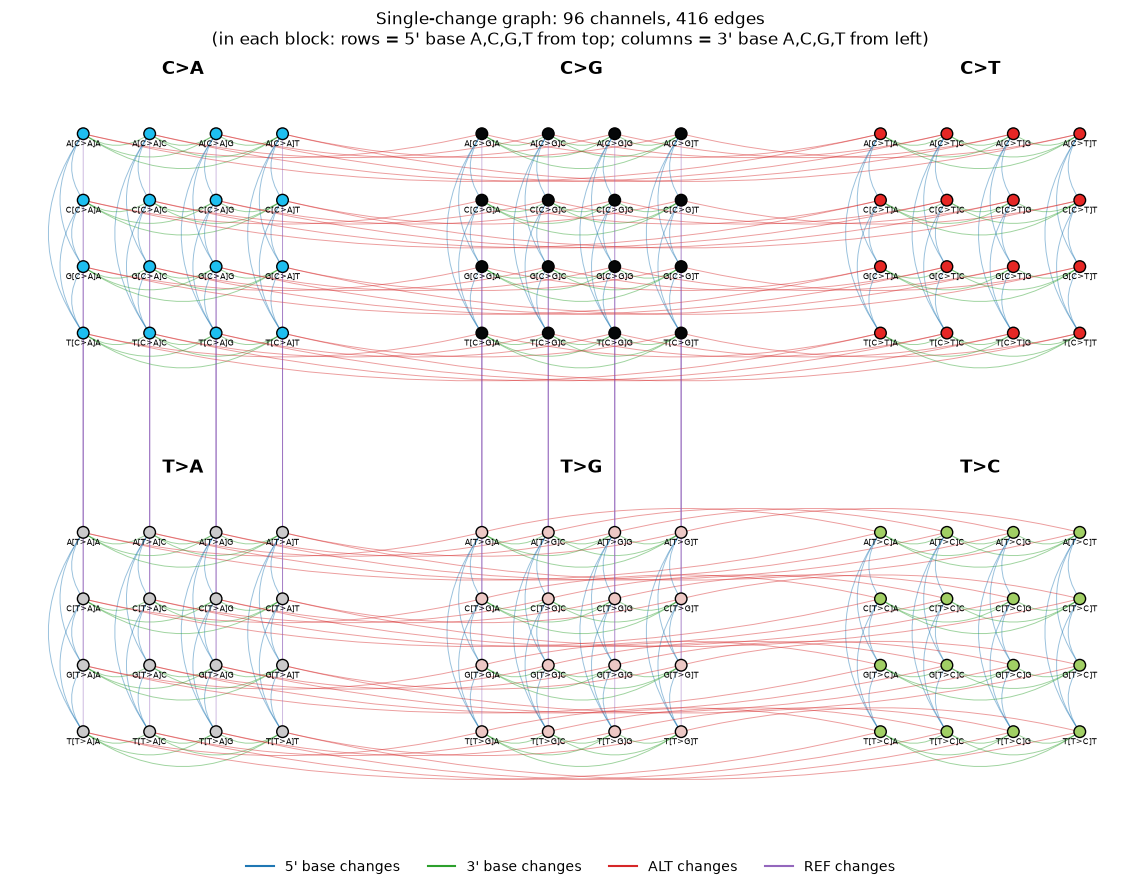

In [ ]:
SUB_COLORS = {"C>A": "#1EBFF0", "C>G": "#050708", "C>T": "#E62725",
              "T>A": "#CBCACB", "T>C": "#A1CF64", "T>G": "#EDC8C5"}
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

# layout: one 4x4 block per substitution (rows = 5' base, columns = 3' base);
# C>* blocks on top, T>* blocks below, placed so that REF changes (C>A-T>A, C>G-T>G) are vertical
BLOCK_POS = {"C>A": (0, 1), "C>G": (1, 1), "C>T": (2, 1),
             "T>A": (0, 0), "T>G": (1, 0), "T>C": (2, 0)}
GAP = 6.0                                                   # distance between blocks
pos = {}
for c in sbs96:
    bx, by = BLOCK_POS[c[2:5]]
    pos[c] = (bx * GAP + BASES.index(c[-1]), by * GAP + 3 - BASES.index(c[0]))

KIND_STYLE = {"prime5":  dict(color="#1f77b4", rad=0.35, label="5' base changes"),
              "prime3": dict(color="#2ca02c", rad=0.35, label="3' base changes"),
              "alt":   dict(color="#d62728", rad=0.12, label="ALT changes"),
              "ref":   dict(color="#9467bd", rad=0.0,  label="REF changes")}

fig, ax = plt.subplots(figsize=(14, 9))
for e in edges.itertuples():
    st = KIND_STYLE[e.kind]
    ax.add_patch(FancyArrowPatch(pos[e.u], pos[e.v], arrowstyle="-", lw=0.7, alpha=0.45,
                                 color=st["color"], connectionstyle=f"arc3,rad={st['rad']}"))
xy = np.array([pos[c] for c in sbs96])
ax.scatter(xy[:, 0], xy[:, 1], s=70, c=[SUB_COLORS[c[2:5]] for c in sbs96], edgecolors="k", zorder=3)
for c in sbs96:
    ax.annotate(c, pos[c], xytext=(0, -9), textcoords="offset points", ha="center", fontsize=5.5, zorder=4)
for s, (bx, by) in BLOCK_POS.items():
    ax.text(bx * GAP + 1.5, by * GAP + 3.9, s, ha="center", fontsize=13, fontweight="bold")
ax.legend(handles=[Line2D([], [], color=v["color"], label=v["label"]) for v in KIND_STYLE.values()],
          loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=4, frameon=False)
ax.set_title("Single-change graph: 96 channels, 416 edges\n(in each block: rows = 5' base A,C,G,T from top; columns = 3' base A,C,G,T from left)", pad=40)
ax.set_aspect("equal")
ax.axis("off")
ax.autoscale()
plt.tight_layout()
plt.show()


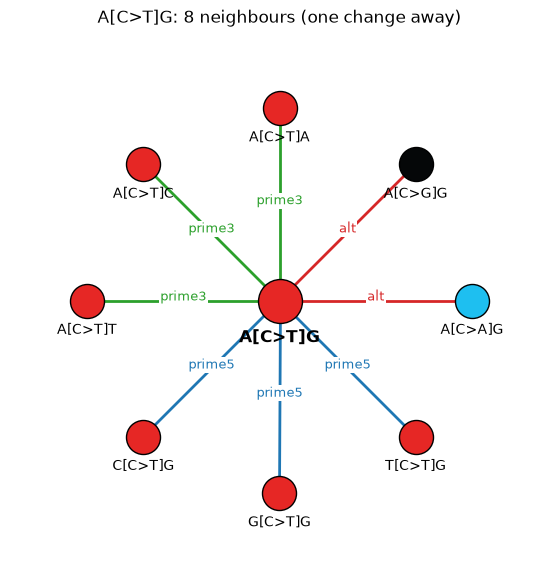

In [ ]:
CENTER = "A[C>T]G"
nb_edges = edges[(edges.u == CENTER) | (edges.v == CENTER)]
neigh = [(e.v if e.u == CENTER else e.u, e.kind) for e in nb_edges.itertuples()]

fig, ax = plt.subplots(figsize=(7, 7))
angles = np.linspace(0, 2 * np.pi, len(neigh), endpoint=False)
for (n, kind), a in zip(neigh, angles):
    x, y = np.cos(a), np.sin(a)
    ax.plot([0, x], [0, y], color=KIND_STYLE[kind]["color"], lw=2)
    ax.scatter(x, y, s=600, color=SUB_COLORS[n[2:5]], edgecolors="k", zorder=3)
    ax.annotate(n, (x, y), xytext=(0, -24), textcoords="offset points", ha="center", fontsize=10)
    ax.annotate(kind, (x / 2, y / 2), ha="center", fontsize=9, color=KIND_STYLE[kind]["color"],
                bbox=dict(fc="white", ec="none", pad=1))
ax.scatter(0, 0, s=1000, color=SUB_COLORS[CENTER[2:5]], edgecolors="k", zorder=3)
ax.annotate(CENTER, (0, 0), xytext=(0, -30), textcoords="offset points", ha="center", fontsize=12, fontweight="bold")
ax.set_title(f"{CENTER}: {len(neigh)} neighbours (one change away)")
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

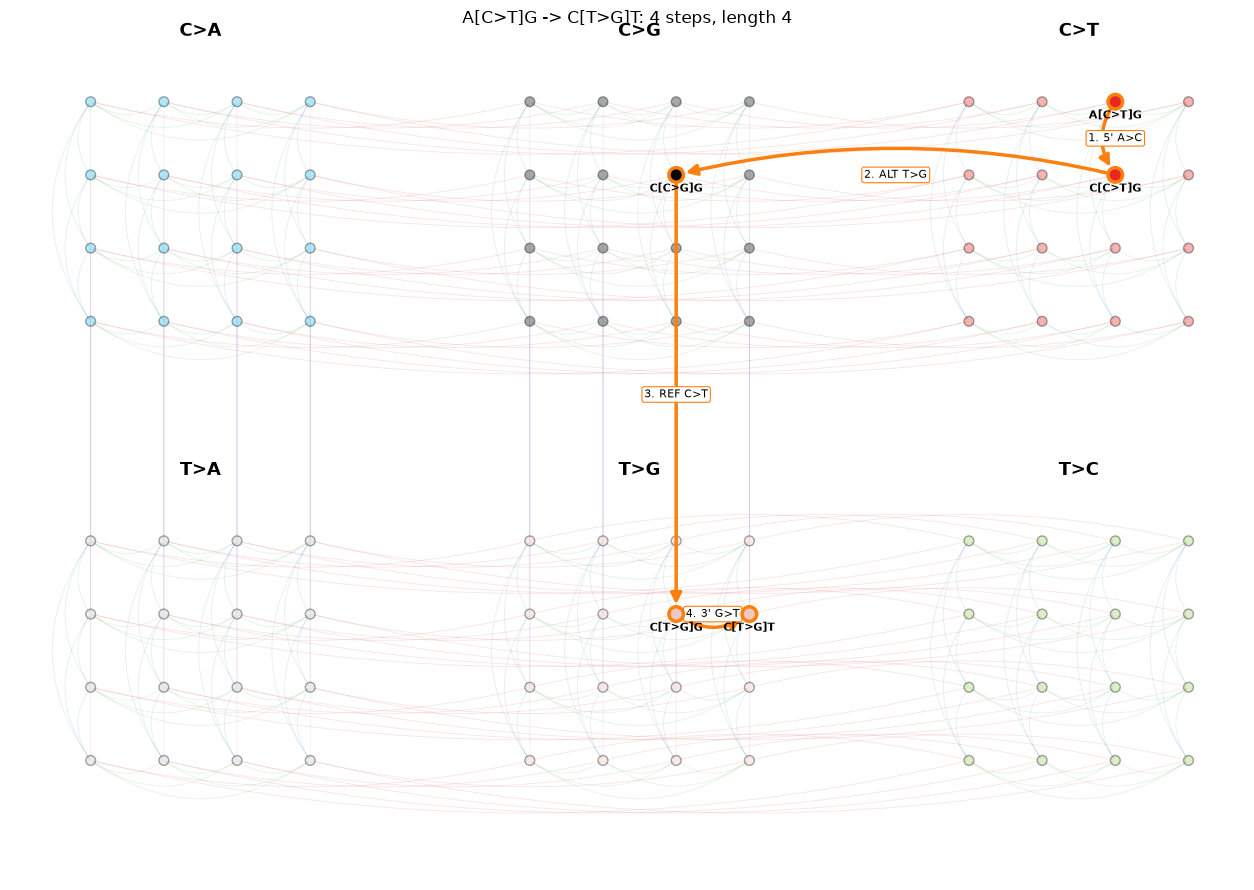

,step,frm,to,kind,change,length,cumulative
0,1,A[C>T]G,C[C>T]G,prime5,5' A>C,1.0,1.0
1,2,C[C>T]G,C[C>G]G,alt,ALT T>G,1.0,2.0
2,3,C[C>G]G,C[T>G]G,ref,REF C>T,1.0,3.0
3,4,C[T>G]G,C[T>G]T,prime3,3' G>T,1.0,4.0


In [ ]:
_, PRED = shortest_path(A, directed=False, return_predecessors=True)   # PRED[i, j] = node before j on a path from i
KIND_LABEL = {"prime5": "5'", "ref": "REF", "alt": "ALT", "prime3": "3'"}


def path_steps(source, target):
    # shortest path from one to another SBS
    i, j = idx[source], idx[target]
    nodes = [j]
    while nodes[-1] != i:
        nodes.append(PRED[i, nodes[-1]])
    nodes = [sbs96[k] for k in nodes[::-1]]
    rows = []
    for u, v in zip(nodes[:-1], nodes[1:]):
        kind = cols[int(np.argmax(parts.loc[u, cols].to_numpy() != parts.loc[v, cols].to_numpy()))]
        rows.append(dict(step=len(rows) + 1, frm=u, to=v, kind=kind,
                         change=f"{KIND_LABEL[kind]} {parts.at[u, kind]}>{parts.at[v, kind]}",
                         length=A[idx[u], idx[v]] + A[idx[v], idx[u]]))
    steps = pd.DataFrame(rows)
    steps["cumulative"] = steps.length.cumsum()
    return steps


def plot_path(source, target, ax=None, color="#ff7f0e"):
    steps = path_steps(source, target)
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 9))
    # full graph, faded
    for e in edges.itertuples():
        st = KIND_STYLE[e.kind]
        ax.add_patch(FancyArrowPatch(pos[e.u], pos[e.v], arrowstyle="-", lw=0.6, alpha=0.12,
                                     color=st["color"], connectionstyle=f"arc3,rad={st['rad']}"))
    ax.scatter(xy[:, 0], xy[:, 1], s=50, c=[SUB_COLORS[c[2:5]] for c in sbs96], edgecolors="k",
               alpha=0.35, zorder=3)
    for s, (bx, by) in BLOCK_POS.items():
        ax.text(bx * GAP + 1.5, by * GAP + 3.9, s, ha="center", fontsize=13, fontweight="bold")
    # the path
    nodes = [source] + steps.to.tolist()
    for st_ in steps.itertuples():
        a, b = pos[st_.frm], pos[st_.to]
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=16, lw=2.5, color=color, zorder=5,
                                     shrinkA=7, shrinkB=7,
                                     connectionstyle=f"arc3,rad={KIND_STYLE[st_.kind]['rad']}"))
        ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2, f"{st_.step}. {st_.change}", fontsize=8, ha="center",
                va="center", zorder=6, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=color, lw=0.8))
    P = np.array([pos[n] for n in nodes])
    ax.scatter(P[:, 0], P[:, 1], s=110, c=[SUB_COLORS[n[2:5]] for n in nodes], edgecolors=color,
               linewidths=2.5, zorder=7)
    for n in nodes:
        ax.annotate(n, pos[n], xytext=(0, -12), textcoords="offset points", ha="center", fontsize=8,
                    fontweight="bold", zorder=8)
    ax.set_title(f"{source} -> {target}: {len(steps)} steps, length {steps.length.sum():g}", pad=30)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.autoscale()
    return steps


sbs1 = "A[C>T]G"
sbs2 = "C[T>G]T"
steps = plot_path(sbs1, sbs2)
plt.tight_layout()
plt.show()
steps